#**Import Dataset**

In [82]:
import pandas as pd
import requests

BASE = "https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/"

FILES = {
    "aps": [
        "APS_2018.csv", "APS_2019.csv", "APS_2020.csv",
        "APS_2021.csv", "APS_2022.csv", "APS_2023.csv"
    ],
    "internet": [
        "Internet_2018.csv", "Internet_2019.csv", "Internet_2020.csv",
        "Internet_2021.csv", "Internet_2022.csv", "Internet_2023.csv"
    ],
    "telekom": [
        "Telekomunikasi_2018.csv", "Telekomunikasi_2019.csv", "Telekomunikasi_2020.csv",
        "Telekomunikasi_2021.csv", "Telekomunikasi_2022.csv", "Telekomunikasi_2023.csv"
    ],
    "pengeluaran": [
        "Pengeluaran_2018.csv", "Pengeluaran_2019.csv", "Pengeluaran_2020.csv",
        "Pengeluaran_2021.csv", "Pengeluaran_2022.csv", "Pengeluaran_2023.csv"
    ]
}

#**Cleaning**

####**Cleaning APS**

In [83]:
def clean_aps(df):
    temp_tahun = df['tahun'].iloc[0] if 'tahun' in df.columns else None

    df = df.drop(index=0).reset_index(drop=True)
    df.columns = df.iloc[0]
    df = df.drop(index=0).reset_index(drop=True)

    prov_col = df.columns[0]
    df = df.rename(columns={prov_col: "provinsi"})
    df = df.loc[:, ~df.columns.astype(str).str.contains("Unnamed")]

    df.columns = (
        df.columns.astype(str)
        .str.strip()
        .str.replace(" ", "_")
        .str.replace("/", "_")
        .str.replace("-", "_")
        .str.lower()
    )

    df = df.dropna(subset=["provinsi"])

    for c in df.columns:
        if c not in ["provinsi", "tahun"]:
            df[c] = pd.to_numeric(df[c], errors="coerce")

    if temp_tahun is not None:
        df["tahun"] = temp_tahun
    return df

####**Cleaning General**

In [84]:
def clean_general(df):
    temp_tahun = df['__tahun'].iloc[0] if '__tahun' in df.columns else None
    df.columns = df.columns.astype(str)

    df = df.loc[:, ~df.columns.astype(str).str.contains("Unnamed")]
    df.columns = (
        df.columns.str.strip()
        .str.lower()
        .str.replace(" ", "_")
        .str.replace("/", "_")
        .str.replace("-", "_")
        .str.replace("+", "_")
    )

    cols = []
    seen = set()
    for col in df.columns:
        original_col = col
        i = 1
        while col in seen:
            col = f"{original_col}_{i}"
            i += 1
        seen.add(col)
        cols.append(col)
    df.columns = cols

    if "provinsi" not in df.columns:

        if len(df.columns) > 0:
            first_col = df.columns[0]
            df = df.rename(columns={first_col: "provinsi"})

        if "provinsi" not in df.columns:
            for c in df.columns:
                if "prov" in c:
                    df = df.rename(columns={c: "provinsi"})
                    break
    df = df.dropna(subset=["provinsi"])

    for c in df.columns:
        if c not in ["provinsi", "tahun"]:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    if temp_tahun is not None:
        df["tahun"] = temp_tahun

    return df

####**Cleaning Pengeluaran**

In [85]:
def clean_pengeluaran(df):
    tahun = df["__tahun"].iloc[0] if "__tahun" in df.columns else None

    df = df.drop(index=0).reset_index(drop=True)

    df.columns = df.iloc[0]
    df = df.drop(index=0).reset_index(drop=True)

    df.columns = df.columns.astype(str)

    df = df.loc[:, ~df.columns.str.contains("Unnamed")]

    df.columns = (
        df.columns
        .str.lower()
        .str.strip()
        .str.replace(" ", "_")
    )

    seen = set()
    new_cols = []
    for col in df.columns:
        base = col
        i = 1
        while col in seen:
            col = f"{base}_{i}"
            i += 1
        seen.add(col)
        new_cols.append(col)
    df.columns = new_cols

    if "provinsi" not in df.columns:
        first_col = df.columns[0]
        df = df.rename(columns={first_col: "provinsi"})

    df = df[df["provinsi"].notna()].reset_index(drop=True)

    for c in df.columns:
        if c != "provinsi":
            df[c] = pd.to_numeric(df[c], errors="coerce")

    if tahun is not None:
        df["tahun"] = tahun

    return df

####**Automasi Cleaning Dataset**

In [86]:
def process_group(group_name):
    all_dfs = []
    file_list = FILES.get(group_name)

    if not file_list:
        print(f"No files found for group: {group_name}")
        return pd.DataFrame()

    for file_name in file_list:
        url = f"{BASE}{file_name}"
        print(f"Processing {url}...")
        try:
            year = file_name.split('_')[-1].split('.')[0]
            if not year.isdigit():
                print(f"Warning: Could not extract year from {file_name}. Skipping year assignment.")
                year = None

            df_to_clean = None
            cleaned_df = None

            if group_name == "aps":
                df_to_clean = pd.read_csv(url)
                df_to_clean["__tahun"] = year
                cleaned_df = clean_aps(df_to_clean)

            elif group_name == "pengeluaran":
                df_to_clean = pd.read_csv(url)
                df_to_clean["__tahun"] = year
                cleaned_df = clean_pengeluaran(df_to_clean)
                pengeluaran_col = None
                for col in cleaned_df.columns:
                    if col not in ["provinsi", "tahun"] and pd.api.types.is_numeric_dtype(cleaned_df[col]):
                        pengeluaran_col = col
                        break
                if pengeluaran_col is not None:
                    cleaned_df = cleaned_df[["provinsi", pengeluaran_col, "tahun"]].copy()
                    cleaned_df = cleaned_df.rename(columns={pengeluaran_col: "pengeluaran"})
                else:
                    print(f"Warning: Could not identify pengeluaran data column in {file_name}.")
                    continue

            elif group_name in ["internet", "telekom"]:
                df_to_clean = pd.read_csv(url)
                df_to_clean["__tahun"] = year
                cleaned_df = clean_pengeluaran(df_to_clean)

                data_col = None
                potential_data_cols = [c for c in cleaned_df.columns if c not in ["provinsi", "tahun"]]

                for col in potential_data_cols:
                    if isinstance(col, str) and ("total" in col.lower() or "jumlah" in col.lower()):
                        data_col = col
                        break

                if data_col is None:
                    for col in potential_data_cols:
                        if pd.api.types.is_numeric_dtype(cleaned_df[col]):
                            data_col = col
                            break

                if data_col:
                    cleaned_df = cleaned_df.rename(columns={data_col: group_name.lower()})
                    cleaned_df = cleaned_df[["provinsi", group_name.lower(), "tahun"]]
                else:
                    print(f"Warning: Could not identify the main data column for '{group_name}' in {file_name}. Skipping. Columns: {cleaned_df.columns.tolist()}")
                    continue

            else:
                print(f"Warning: No specific cleaning function for group: {group_name}. Skipping {file_name}.")
                continue

            if cleaned_df is not None:
                all_dfs.append(cleaned_df)

        except Exception as e:
            print(f"Error processing {url}: {e}")
            continue

    if all_dfs:
        return pd.concat(all_dfs, ignore_index=True)
    else:
        return pd.DataFrame()

df_aps = process_group("aps")
df_internet = process_group("internet")
df_telekomunikasi = process_group("telekom")
df_pengeluaran = process_group("pengeluaran")

Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/APS_2018.csv...
Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/APS_2019.csv...
Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/APS_2020.csv...
Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/APS_2021.csv...
Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/APS_2022.csv...
Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/APS_2023.csv...
Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/Internet_2018.csv...
Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/Internet_2019.csv...
Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/Internet_2020.cs

####**Penghapusan Kolom Tahun Duplikat**

In [87]:
import pandas as pd

def remove_duplicate_year_columns(df):
    """
    Menghapus kolom tahun dobel seperti:
    2018, 2019, 2020, 2021, 2022, 2023
    """
    year_cols = [col for col in df.columns if str(col).isdigit()]

    df = df.drop(columns=year_cols, errors="ignore")

    return df

df_aps = remove_duplicate_year_columns(df_aps)
df_aps.to_csv("APS_all_clean.csv", index=False)

df_internet = remove_duplicate_year_columns(df_internet)
df_internet.to_csv("Internet_all_clean.csv", index=False)

df_telekomunikasi = remove_duplicate_year_columns(df_telekomunikasi)
df_telekomunikasi.to_csv("Telekomunikasi_all_clean.csv", index=False)

df_pengeluaran = remove_duplicate_year_columns(df_pengeluaran)
df_pengeluaran.to_csv("Pengeluaran_all_clean.csv", index=False)

print("Semua kolom tahun dobel berhasil dihapus dan file sudah tersimpan ulang!")

Semua kolom tahun dobel berhasil dihapus dan file sudah tersimpan ulang!


####**Transformasi Long Wide Pengeluaran**

In [88]:
import pandas as pd
import glob
import os
import re
file_list = FILES.get("pengeluaran")

if not file_list:
    print("Error: No pengeluaran files defined in FILES dictionary.")

hasil = []

for file_name in file_list:
    url = f"{BASE}{file_name}"
    print(f"Processing {url}...")

    match = re.search(r'Pengeluaran_(\d{4})\.csv', file_name)
    if match:
        year = int(match.group(1))
    else:
        print(f"Warning: Could not extract year from filename {file_name}. Skipping.")
        continue

    try:
        df_raw = pd.read_csv(url)
        df_raw["__tahun"] = year

        df_cleaned = clean_pengeluaran(df_raw.copy())

        pengeluaran_col = None
        for col in df_cleaned.columns:
            if col not in ["provinsi", "tahun"] and pd.api.types.is_numeric_dtype(df_cleaned[col]):
                pengeluaran_col = col
                break

        if pengeluaran_col is None:
            print(f"Warning: Could not identify the pengeluaran data column in {file_name}. Skipping.")
            continue

        df_long = df_cleaned[["provinsi", pengeluaran_col, "tahun"]].copy()
        df_long = df_long.rename(columns={pengeluaran_col: "pengeluaran"})

        df_long["tahun"] = df_long["tahun"].astype(int)
        df_long["provinsi"] = df_long["provinsi"].str.upper().str.strip()
        df_long["pengeluaran"] = pd.to_numeric(df_long["pengeluaran"], errors="coerce")

        hasil.append(df_long)
    except Exception as e:
        print(f"Error processing {url}: {e}")
        continue
df_all = pd.concat(hasil, ignore_index=True)

df_wide = df_all.pivot_table(
    index="provinsi",
    columns="tahun",
    values="pengeluaran"
).reset_index()

kolom = [col for col in df_wide.columns if col == "provinsi"] + sorted([c for c in df_wide.columns if c != "provinsi"])
df_wide = df_wide[kolom]
df_all.to_csv("Pengeluaran_all_clean.csv", index=False)

df_all.head()

Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/Pengeluaran_2018.csv...
Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/Pengeluaran_2019.csv...
Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/Pengeluaran_2020.csv...
Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/Pengeluaran_2021.csv...
Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/Pengeluaran_2022.csv...
Processing https://raw.githubusercontent.com/desnanty/Project-Data-Wrangling-Kelompok-23/main/Pengeluaran_2023.csv...


,provinsi,pengeluaran,tahun
0,ACEH,9186.0,2018
1,SIMEULUE,6824.0,2018
2,ACEH SINGKIL,8506.0,2018
3,ACEH SELATAN,7891.0,2018
4,ACEH TENGGARA,7685.0,2018


####**Cek Missing Value**

In [89]:
print("Jumlah missing values per kolom:")
df_all.isnull().sum()

Jumlah missing values per kolom:


,0
provinsi,0
pengeluaran,180
tahun,0


####**Cek Duplikasi Data**

In [90]:
print("Jumlah duplikasi sebelum dibersihkan:", df_all.duplicated().sum())
df_all = df_all.drop_duplicates()

Jumlah duplikasi sebelum dibersihkan: 0


####**Statistik Deskriptif Pengeluaran**

In [91]:
df_all.describe()

,pengeluaran,tahun
count,3294.000000,3474.000000
mean,10501.562234,2020.500000
std,2701.609823,1.708071
min,3975.000000,2018.000000
25%,8744.500000,2019.000000
50%,10328.500000,2020.500000
75%,11855.750000,2022.000000
max,24975.000000,2023.000000


####**Pivot Data Pengeluaran**

In [92]:
df_wide = df_all.pivot_table(
    index="provinsi",
    columns="tahun",
    values="pengeluaran"
).reset_index()

df_wide

tahun,provinsi,2018,2019,2020,2021,2022,2023
0,ACEH,9186.0,9603.0,9492.0,9572.0,9963.0,10334.0
1,ACEH BARAT,9134.0,9692.0,9516.0,9593.0,9775.0,10085.0
2,ACEH BARAT DAYA,8093.0,8491.0,8316.0,8428.0,8651.0,9043.0
3,ACEH BESAR,9192.0,9661.0,9641.0,9644.0,9894.0,10309.0
4,ACEH JAYA,9262.0,9682.0,9615.0,9666.0,10041.0,10461.0
...,...,...,...,...,...,...,...
543,WAY KANAN,8979.0,9292.0,9102.0,9173.0,9450.0,9887.0
544,WONOGIRI,9117.0,9426.0,9286.0,9429.0,9780.0,10283.0
545,WONOSOBO,10503.0,10871.0,10621.0,10760.0,11108.0,11577.0
546,YAHUKIMO,4737.0,5030.0,4875.0,4895.0,5101.0,5351.0


####**Penyimpanan Dataset**

In [93]:
df_all.to_csv("pengeluaran_all_long_clean.csv", index=False)
df_wide.to_csv("pengeluaran_all_wide_clean.csv", index=False)

####**Statistik per Tahun (GroupBy)**

In [94]:
stat_per_tahun = df_all.groupby("tahun")["pengeluaran"].describe()
stat_per_tahun

,count,mean,std,min,25%,50%,75%,max
tahun,,,,,,,,
2018,549.0,10177.956284,2624.550038,4131.0,8456.0,10048.0,11499.0,23363.0
2019,549.0,10473.923497,2682.342630,4181.0,8715.0,10316.0,11791.0,23851.0
2020,549.0,10287.475410,2663.499125,3975.0,8593.0,10163.0,11614.0,23575.0
2021,549.0,10353.222222,2686.757702,3976.0,8638.0,10220.0,11716.0,23888.0
2022,549.0,10671.861566,2722.170519,4190.0,8951.0,10560.0,12069.0,24221.0
2023,549.0,11044.934426,2748.445043,4352.0,9350.0,10948.0,12480.0,24975.0


####**Load Dataset Akhir**

In [95]:
import pandas as pd
import glob
import os

def load_dataset(prefix):
    files = glob.glob(f"./{prefix}_*.csv")
    hasil = []

    for f in files:
        df = pd.read_csv(f)
        df.columns = df.columns.str.strip()

        prov_col = df.columns[0]
        nilai_col = df.columns[1]
        tahun_col = df.columns[2]

        df = df.rename(columns={
            prov_col: "provinsi",
            nilai_col: prefix.lower(),
            tahun_col: "tahun"
        })

        df["provinsi"] = df["provinsi"].str.upper().str.strip()
        df["tahun"] = df["tahun"].astype(int)
        df[prefix.lower()] = pd.to_numeric(df[prefix.lower()], errors="coerce")

        hasil.append(df)

    df_all = pd.concat(hasil, ignore_index=True)
    return df_all

#**Mergin**

In [96]:
import pandas as pd

aps = pd.read_csv('APS_all_clean.csv')
pengeluaran = pd.read_csv('Pengeluaran_all_clean.csv')

internet = df_internet.copy()
telekom = df_telekomunikasi.copy()
internet['tahun'] = internet['tahun'].astype(int)
telekom['tahun'] = telekom['tahun'].astype(int)

def std(df):
    df["provinsi"] = df["provinsi"].astype(str).str.upper().str.strip()
    return df

aps = std(aps)
internet = std(internet)
pengeluaran = std(pengeluaran)
telekom = std(telekom)

dfY = aps[["provinsi", "19_23"]].copy()
dfY = dfY.rename(columns={"19_23": "partisipasi_sekolah"})
dfY["tahun"] = 2023

dfX1 = internet[internet["tahun"] == 2023]
dfX1 = dfX1.groupby("provinsi", as_index=False)["internet"].mean()
dfX1 = dfX1.rename(columns={"internet": "akses_internet"})

dfX2 = pengeluaran[pengeluaran["tahun"] == 2023]
dfX2 = dfX2.groupby("provinsi", as_index=False)["pengeluaran"].mean()
dfX2 = dfX2.rename(columns={"pengeluaran": "pengeluaran_perkapita"})

dfX3 = telekom.groupby("provinsi", as_index=False)["telekom"].mean()
dfX3 = dfX3.rename(columns={"telekom": "konsumsi_telekomunikasi"})

dataset_final = dfY.merge(dfX1, on="provinsi", how="left")
dataset_final = dataset_final.merge(dfX2, on="provinsi", how="left")
dataset_final = dataset_final.merge(dfX3, on="provinsi", how="left")

dataset_final = dataset_final[
    ["provinsi","tahun",
     "partisipasi_sekolah",
     "akses_internet",
     "pengeluaran_perkapita",
     "konsumsi_telekomunikasi"]
]

dataset_final.to_csv("dataset_final_analysis.csv", index=False)
dataset_final.head(10)


from google.colab import files
files.download("dataset_final_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **EDA**

**Statistik Deskriptif Awal**

In [97]:
dataset_final.describe()

,tahun,partisipasi_sekolah,akses_internet,pengeluaran_perkapita,konsumsi_telekomunikasi
count,234.0,210.000000,210.000000,198.000000,210.000000
mean,2023.0,29.777714,92.155429,11260.651515,4.058095
std,0.0,6.993264,2.823327,2095.249560,0.571043
min,2023.0,18.450000,84.080000,7562.000000,2.991667
25%,2023.0,25.190000,91.010000,10117.000000,3.615000
50%,2023.0,28.005000,92.780000,11172.000000,3.921667
75%,2023.0,33.555000,93.910000,11878.000000,4.370000
max,2023.0,56.810000,98.080000,19373.000000,5.433333


**Pemeriksaan Missing Values**

In [98]:
dataset_final.isnull().sum()

,0
provinsi,0
tahun,0
partisipasi_sekolah,24
akses_internet,24
pengeluaran_perkapita,36
konsumsi_telekomunikasi,24


**Konversi Numerik dan Penanganan Missing Value**

In [99]:
for col in ["partisipasi_sekolah", "akses_internet", "pengeluaran_perkapita", "konsumsi_telekomunikasi"]:
    dataset_final[col] = pd.to_numeric(dataset_final[col], errors="coerce")

dataset_final["partisipasi_sekolah"] = dataset_final["partisipasi_sekolah"].fillna(dataset_final["partisipasi_sekolah"].mean())
dataset_final["akses_internet"] = dataset_final["akses_internet"].fillna(dataset_final["akses_internet"].mean())
dataset_final["pengeluaran_perkapita"] = dataset_final["pengeluaran_perkapita"].fillna(dataset_final["pengeluaran_perkapita"].median())
dataset_final["konsumsi_telekomunikasi"] = dataset_final["konsumsi_telekomunikasi"].fillna(dataset_final["konsumsi_telekomunikasi"].mean())

print(dataset_final.isnull().sum())


provinsi                   0
tahun                      0
partisipasi_sekolah        0
akses_internet             0
pengeluaran_perkapita      0
konsumsi_telekomunikasi    0
dtype: int64


**Analisis Korelasi Antar Variabel**

In [100]:
corr = dataset_final[[
    "partisipasi_sekolah",
    "akses_internet",
    "pengeluaran_perkapita",
    "konsumsi_telekomunikasi"
]].corr()

corr

,partisipasi_sekolah,akses_internet,pengeluaran_perkapita,konsumsi_telekomunikasi
partisipasi_sekolah,1.000000,0.114663,-0.174607,0.202002
akses_internet,0.114663,1.000000,0.248748,0.266470
pengeluaran_perkapita,-0.174607,0.248748,1.000000,-0.562918
konsumsi_telekomunikasi,0.202002,0.266470,-0.562918,1.000000


In [101]:
import matplotlib.pyplot as plt
import seaborn as sns

####**Scatter Plot Hubungan Akses Internet dan Partisipasi Sekolah**

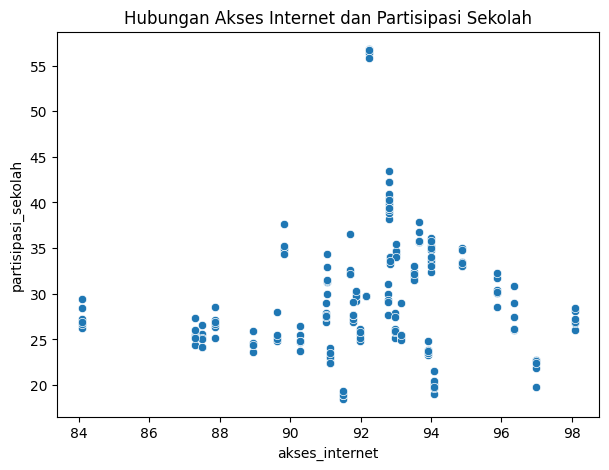

In [102]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    data=dataset_final,
    x="akses_internet",
    y="partisipasi_sekolah"
)
plt.title("Hubungan Akses Internet dan Partisipasi Sekolah")
plt.show()

####**Scatter Plot Hubungan Pengeluaran Per Kapita dan Partisipasi Sekolah**

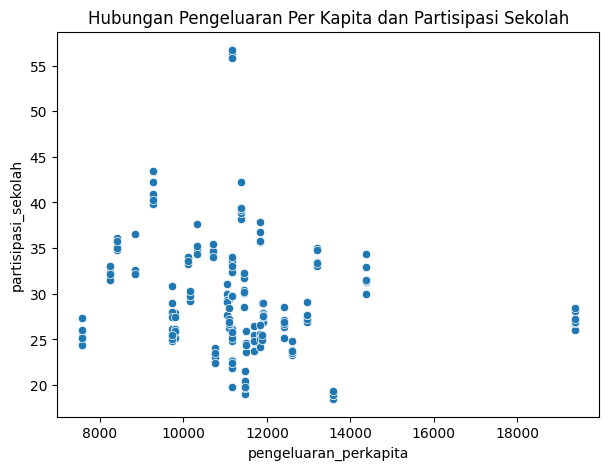

In [103]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    data=dataset_final,
    x="pengeluaran_perkapita",
    y="partisipasi_sekolah"
)
plt.title("Hubungan Pengeluaran Per Kapita dan Partisipasi Sekolah")
plt.show()

####**Scatter Plot Hubungan Konsumsi Telekomunikasi dan Partisipasi Sekolah**

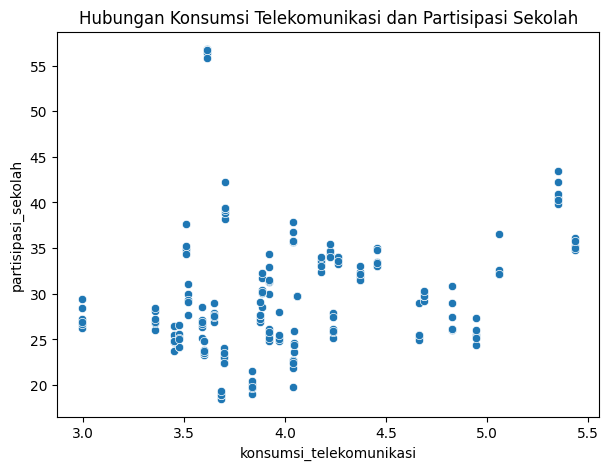

In [104]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    data=dataset_final,
    x="konsumsi_telekomunikasi",
    y="partisipasi_sekolah"
)
plt.title("Hubungan Konsumsi Telekomunikasi dan Partisipasi Sekolah")
plt.show()

####**Heatmap Korelasi Antar Variabel**

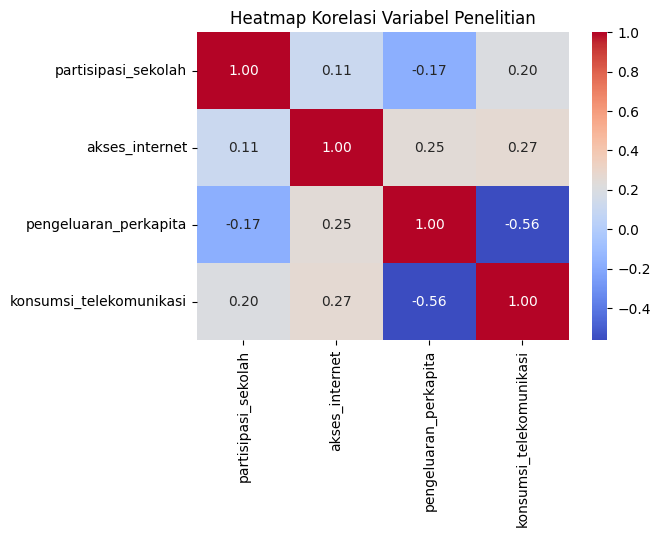

In [105]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Heatmap Korelasi Variabel Penelitian")
plt.show()

####**Analisis Distribusi Variabel Menggunakan Histogram**

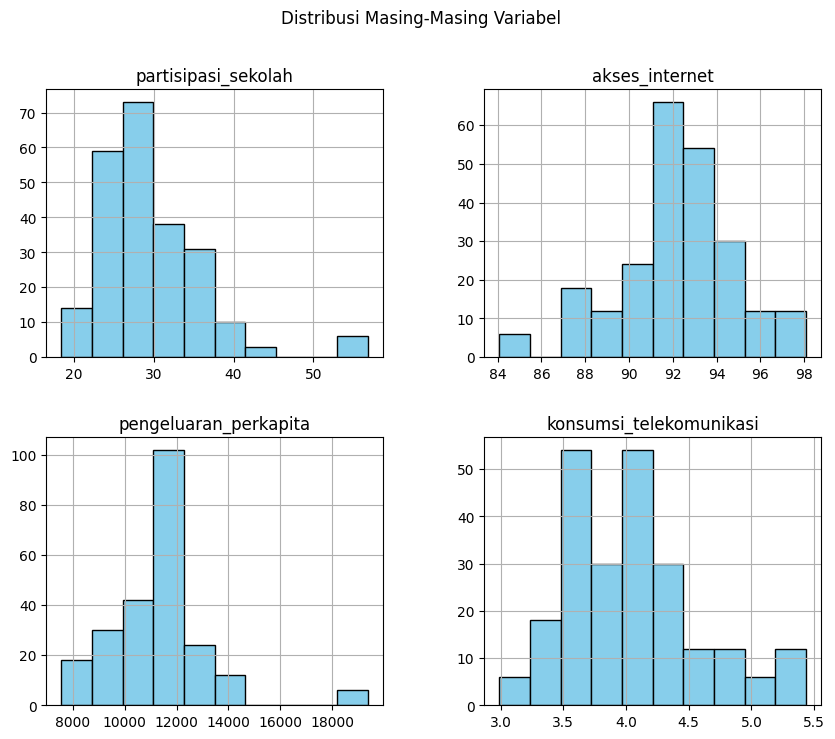

In [106]:
dataset_final[[
    "partisipasi_sekolah",
    "akses_internet",
    "pengeluaran_perkapita",
    "konsumsi_telekomunikasi"
]].hist(figsize=(10,8), bins=10, color="skyblue", edgecolor="black")
plt.suptitle("Distribusi Masing-Masing Variabel")
plt.show()

####**Analisis Persebaran dan Outlier Menggunakan Boxplot**

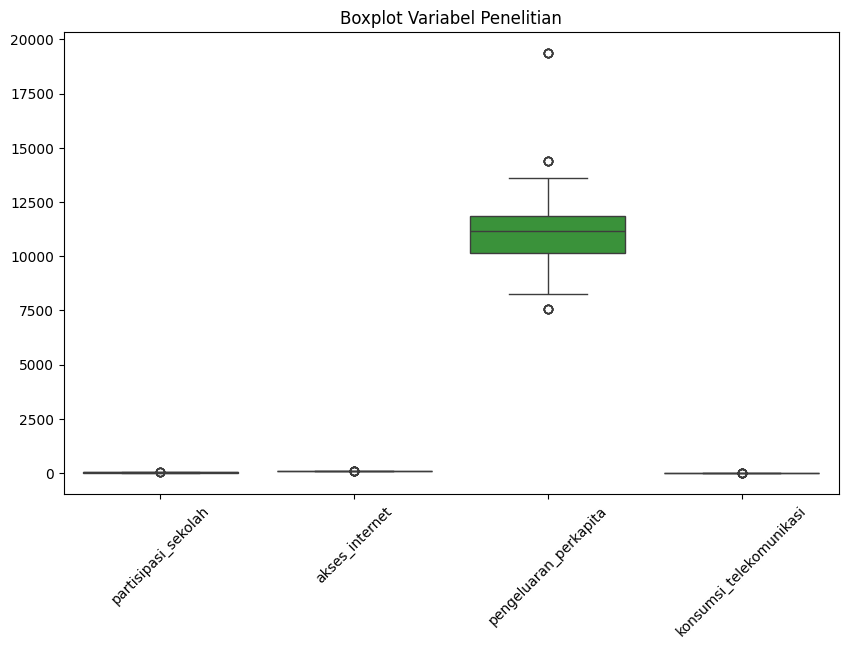

In [107]:
plt.figure(figsize=(10,6))
sns.boxplot(data=dataset_final[[
    "partisipasi_sekolah",
    "akses_internet",
    "pengeluaran_perkapita",
    "konsumsi_telekomunikasi"
]])
plt.xticks(rotation=45)
plt.title("Boxplot Variabel Penelitian")
plt.show()

####**Pairplot Hubungan Antar Variabel**

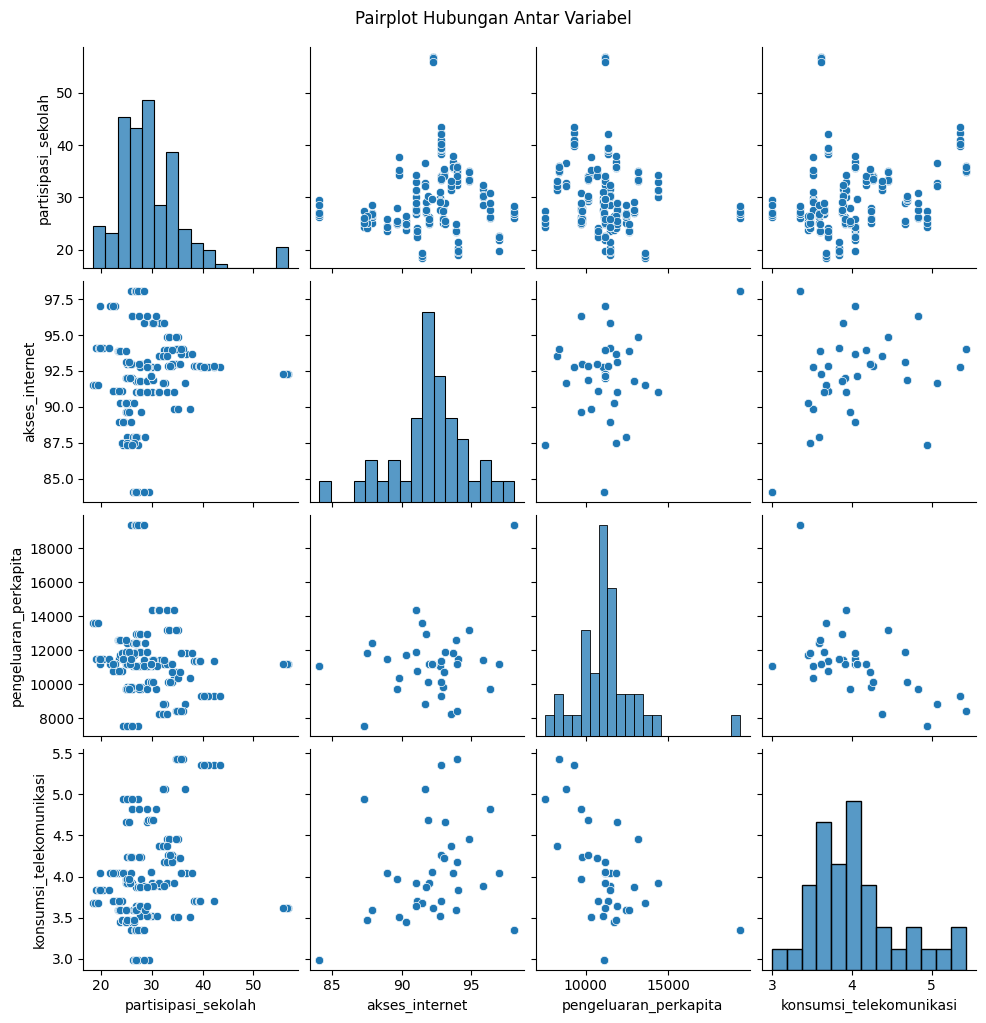

In [108]:
sns.pairplot(dataset_final[[
    "partisipasi_sekolah",
    "akses_internet",
    "pengeluaran_perkapita",
    "konsumsi_telekomunikasi"
]])
plt.suptitle("Pairplot Hubungan Antar Variabel", y=1.02)
plt.show()

#**Modeling**

####**Pembersihan Data untuk Modeling dan Penentuan Variabel Dependen dan Independen**

In [109]:
import statsmodels.api as sm
import pandas as pd

In [110]:
Y = dataset_final["partisipasi_sekolah"]
X = dataset_final[[
    "akses_internet",
    "pengeluaran_perkapita",
    "konsumsi_telekomunikasi"
]]

X = sm.add_constant(X)

In [111]:
dataset_final.columns

Index(['provinsi', 'tahun', 'partisipasi_sekolah', 'akses_internet',
       'pengeluaran_perkapita', 'konsumsi_telekomunikasi'],
      dtype='object')

In [112]:
dataset_final.to_csv("Analisis_Partisipasi_Sekolah_Indonesia.csv", index=False)

####**Pembentukan Model Regresi Linear Berganda (OLS)**

In [113]:
dataset_final_clean = dataset_final.dropna()

Y = dataset_final_clean["partisipasi_sekolah"]
X = dataset_final_clean[["akses_internet", "pengeluaran_perkapita", "konsumsi_telekomunikasi"]]
X = sm.add_constant(X)

model = sm.OLS(Y, X).fit()
print(model.summary())

                             OLS Regression Results                            
Dep. Variable:     partisipasi_sekolah   R-squared:                       0.060
Model:                             OLS   Adj. R-squared:                  0.047
Method:                  Least Squares   F-statistic:                     4.857
Date:                 Sun, 21 Dec 2025   Prob (F-statistic):            0.00270
Time:                         08:45:03   Log-Likelihood:                -766.74
No. Observations:                  234   AIC:                             1541.
Df Residuals:                      230   BIC:                             1555.
Df Model:                            3                                         
Covariance Type:             nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const           